# 02 — GloVe + BiLSTM (attention): baseline, random search and error analysis

Second model of the project: **GloVe 6B 100d** word vectors feeding a **bidirectional LSTM** with attention pooling.
Trained on `data/processed/train_split.json` and evaluated on `data/processed/val_split.json` (the shared stratified 85/15 split, seed 42). The unlabeled test reviews are never loaded here.

Reusable code is in `src/glove_bilstm.py`. This notebook first trains and evaluates the **baseline** (one reasonable set of default settings, before any tuning), then runs a **random search** over hidden units, layers, learning rate, dropout and batch size, compares the best setting with the baseline, analyses its errors, and finally checks what the GloVe initialisation contributes.

## What the baseline is

```
review  ->  tokenize  ->  ids (vocab)  ->  GloVe vectors (frozen)  ->  BiLSTM (128 per direction)  ->  attention pooling  ->  dropout 0.4  ->  2 class scores
"Not good!"  [not, good, !]   [30, 41, 20]     (L, 100) matrix            (L, 256) states                (256,) vector                            [neg, pos]
```

| Setting | Baseline value |
|---|---|
| Embeddings | GloVe 6B 100d, **frozen** |
| BiLSTM | 1 layer, hidden 128 per direction, bidirectional |
| Pooling | attention |
| Dropout | 0.4 |
| Loss / optimizer | cross-entropy (unweighted) / AdamW, learning rate 1e-3, gradient clipping 1.0 |
| Batch size / max length | 64 / 150 tokens |
| Epochs | up to 15; early stopping keeps the epoch with the best validation Negative F1 (stops after 3 epochs without improvement) |

**Why Negative F1 is the headline metric:** only ~15% of reviews are negative, so accuracy barely moves: always answering "positive" already scores ~85%. Negative F1 is the F1 score of the negative class.

**Reproducibility:** the baseline is trained with 3 seeds (42, 43, 44) and reported as mean ± std; the seed-to-seed spread also shows how noisy a single run is. Results are cached in `results/bilstm/` (git-ignored) by the exact settings, so re-running the notebook never repeats work.

In [1]:
# ==================== SETUP ====================
import hashlib                   # short fingerprint of a run's settings (cache key)
import json                      # save/load small result files
import time                      # wall-clock timing
from pathlib import Path

import matplotlib.pyplot as plt  # curves, confusion matrices, search plots
import numpy as np
import pandas as pd

# All model logic lives in src/glove_bilstm.py ; the notebook only calls it.
from src.glove_bilstm import (
    BiLSTMClassifier, build_embedding_matrix, build_vocab, download_glove, encode,
    load_glove, load_split, predict_proba, set_seed, train_model,
)

SEED = 42        # fixed seed for every tuning run, so differences come from the setting, not luck
MAX_LEN = 150    # every review becomes exactly 150 tokens (words + punctuation). About 94% of training
                 # reviews fit; longer ones keep their first 150 tokens.
DEVICE = "cpu"   # CPU runs from a clean start are reproducible; the Apple GPU backend is not guaranteed to be
RESULTS = Path("results/bilstm")
for sub in ("probs", "histories"):
    (RESULTS / sub).mkdir(parents=True, exist_ok=True)   # P(positive) per validation review / per-epoch history
set_seed(SEED)

In [2]:
# ==================== DATA, VOCABULARY, EMBEDDINGS (training split only) ====================
# 1) Load the shared splits made by 00_Data_Preparation.ipynb: (list of review strings, list of 0/1 labels).
#    Example: train_texts[0] = "definitely like this boot. it does run small around the calf. ..." and train_y[0] = 1
train_texts, train_y = load_split("data/processed/train_split.json")   # 6,104 reviews: used to learn
val_texts, val_y = load_split("data/processed/val_split.json")         # 1,078 reviews: used to evaluate

# 2) Vocabulary: word -> integer id from TRAINING reviews only (using validation words would leak information).
#    Words seen fewer than 2 times are dropped and later map to <unk>.
#    Example: {"<pad>": 0, "<unk>": 1, "the": 3, "not": 30, "great": 32, ...}  -> 7,066 entries
vocab = build_vocab(train_texts, min_freq=2)

# 3) GloVe: download once (~822 MB zip; only the 100-dim file is kept) into {word: 100 numbers}.
#    Example: glove["good"] = [-0.031, 0.120, 0.539, -0.437, ...]  (400,000 words)
glove = load_glove(download_glove("data/glove"), dim=100)

# 4) Two possible starting points for the embedding layer, one row per vocabulary id:
#    Pretrained GloVe vectors, one row per vocabulary id, shape (7066, 100). Words GloVe lacks (e.g. "it's")
#    get a small random vector; <pad> is all zeros.
emb = build_embedding_matrix(vocab, glove, dim=100, seed=SEED)

# 5) Encode each review as exactly MAX_LEN ids: lowercase + split into words/punctuation, look up each token
#    (unknown -> 1), cut to 150, pad with 0.
#    Example (MAX_LEN=12): "I did not like this movie, it was bad!"
#      tokens: [i, did, not, like, this, movie, ",", it, was, bad, "!"]
#      ids:    [4, 156, 30, 38, 14, 1408, 5, 9, 22, 418, 20, 0]   <- last 0 is padding
X_train = [encode(t, vocab, MAX_LEN) for t in train_texts]
X_val = [encode(t, vocab, MAX_LEN) for t in val_texts]

# Sanity numbers for the report: GloVe coverage (the uncovered words are mostly contractions such as "it's"
# and "don't": GloVe stores them as "it" + "'s" but our tokenizer keeps the apostrophe inside the word) and
# the class balance, which should match between train and validation (~0.854 positive).
coverage = sum(w in glove for w in vocab) / len(vocab)
print(f"train {len(X_train)} | val {len(X_val)} | vocab {len(vocab)} | GloVe coverage {coverage:.1%}")
print(f"positive share  train {np.mean(train_y):.3f} | val {np.mean(val_y):.3f}")

train 6104 | val 1078 | vocab 7066 | GloVe coverage 93.9%
positive share  train 0.854 | val 0.854


In [3]:
# ==================== RUN MACHINERY (cached by exact settings) ====================
# The baseline: sensible defaults, before any tuning. The random search overrides hidden, layers, lr, dropout and
# batch_size; Everything else stays as written here.
BASELINE = dict(
    init="glove",          # embeddings are always pretrained GloVe (kept in the config so cached run keys stay valid)
    freeze=True,           # True: GloVe vectors are not updated by training; False: they are fine-tuned (not searched)
    hidden=128,            # LSTM state size per direction; the BiLSTM output per word is 2 x 128 = 256 numbers
    layers=1,              # stacked LSTM layers (searched: 1 or 2)
    dropout=0.4,           # randomly zero 40% of the review vector during training (searched; reduces overfitting)
    pooling="attention",   # how per-word states become one review vector: attention | max | last
    bidirectional=True,    # read left-to-right and right-to-left (not searched)
    class_weighted=False,  # True: mistakes on the rare negative class cost more in the loss
    lr=1e-3,               # learning rate: size of each weight update (0.001)
    batch_size=64,         # reviews per update step (searched)
    seed=SEED,
)

csv_path = RESULTS / "runs.csv"
RUNS = {r["key"]: r for r in pd.read_csv(csv_path).to_dict("records")} if csv_path.exists() else {}


def config_key(config):
    """Short fingerprint of the exact settings. Same settings -> same key -> the saved run is reused.
    Example: the baseline candidate of the random search equals the seed-42 baseline run, so it is not trained twice."""
    return hashlib.md5(json.dumps(config, sort_keys=True).encode()).hexdigest()[:8]


def get_run(config, label):
    """Return the result row for this configuration, training it only if it has not been run before."""
    key = config_key(config)
    if key not in RUNS:
        print(f"[train] {label}  (key {key})")
        set_seed(config["seed"])
        # Shapes per batch of B reviews: ids (B, L) -> embeddings (B, L, 100) -> BiLSTM (B, L, 2*hidden)
        #   -> pooled (B, 2*hidden) -> logits (B, 2). L is the longest real review in the batch (at most 150).
        model = BiLSTMClassifier(
            emb, hidden=config["hidden"], layers=config["layers"],
            dropout=config["dropout"], pooling=config["pooling"], bidirectional=config["bidirectional"],
            freeze_embeddings=config["freeze"],
        )
        # AdamW + cross-entropy. After every epoch the model is scored on the validation set; training stops
        # after 3 epochs without a better validation Negative F1 and the best epoch's weights are restored.
        res = train_model(
            model, X_train, train_y, X_val, val_y, lr=config["lr"], batch_size=config["batch_size"],
            class_weighted=config["class_weighted"], seed=config["seed"], device=DEVICE, verbose=True,
        )
        # Keep P(positive) per validation review (PR curve, error analysis) and the per-epoch history (curves).
        np.save(RESULTS / "probs" / f"{key}.npy", predict_proba(model, X_val, device=DEVICE))
        (RESULTS / "histories" / f"{key}.json").write_text(json.dumps(res["history"]))
        m = res["metrics"]
        RUNS[key] = {
            "key": key, "config": json.dumps(config, sort_keys=True), "best_epoch": res["best_epoch"],
            "accuracy": m["accuracy"], "precision": m["precision"], "recall": m["recall"], "f1": m["f1"],
            "neg_f1": m["neg_f1"], "pr_auc": m["pr_auc"], "train_seconds": round(res["train_seconds"], 1),
            # trainable parameters only: frozen embedding vectors are not counted (fine-tuning adds ~0.7M)
            "trainable_params": sum(p.numel() for p in model.parameters() if p.requires_grad),
        }
        pd.DataFrame(RUNS.values()).to_csv(csv_path, index=False)   # save immediately: safe to interrupt
    return {**RUNS[key], "label": label}

In [4]:
# ==================== TRAIN THE BASELINE (3 SEEDS) ====================
# The same baseline trained with 3 different seeds (different initialisation and batch order). The spread of
# its Negative F1 tells us how big a difference must be before it means anything.
# Example: if the three scores are 0.69, 0.71, 0.70, the spread is ~0.01, so a candidate that is 0.005 better
# than another is NOT really better.
baseline_rows = [get_run({**BASELINE, "seed": s}, f"baseline seed {s}") for s in (42, 43, 44)]
baseline_negf1 = [r["neg_f1"] for r in baseline_rows]
NOISE = max(float(np.std(baseline_negf1, ddof=1)), 0.01)   # sample std of 3 seeds, floored at 0.01
print(f"baseline Negative F1 over 3 seeds: {np.round(baseline_negf1, 4)}")
print(f"NOISE band = {NOISE:.4f}  (a tuned setting must beat the baseline by more than this to count as a real improvement)")

baseline Negative F1 over 3 seeds: [0.6688 0.6426 0.6507]
NOISE band = 0.0134  (a tuned setting must beat the baseline by more than this to count as a real improvement)


In [5]:
# ==================== BASELINE RESULTS TABLE ====================
# One row per seed, then mean +- std over the 3 seeds (sample std, n = 3).
# Example: neg_f1 0.6540 +- 0.0134 means the three runs scored about 0.64-0.67, i.e. a single run can be off by
# ~0.01 either way, so differences smaller than that between two settings should not be trusted.
metric_keys = ["accuracy", "precision", "recall", "f1", "neg_f1", "pr_auc", "train_seconds"]
table = pd.DataFrame(baseline_rows)[["label", "best_epoch"] + metric_keys + ["trainable_params"]]
display(table.round(4))

summary = {
    "config": BASELINE,
    "seeds": {str(json.loads(r["config"])["seed"]): {k: float(r[k]) for k in metric_keys} for r in baseline_rows},
    "mean": {k: float(np.mean([r[k] for r in baseline_rows])) for k in metric_keys},
    "std": {k: float(np.std([r[k] for r in baseline_rows], ddof=1)) for k in metric_keys},
}
(RESULTS / "baseline_summary.json").write_text(json.dumps(summary, indent=2))
for k in metric_keys:
    print(f"{k:14s} {summary['mean'][k]:.4f} ± {summary['std'][k]:.4f}")

,label,best_epoch,accuracy,precision,recall,f1,neg_f1,pr_auc,train_seconds,trainable_params
0,baseline seed 42,14,0.9035,0.9435,0.9435,0.9435,0.6688,0.9763,245.7,236291
1,baseline seed 43,7,0.8989,0.9366,0.9457,0.9411,0.6426,0.9808,158.8,236291
2,baseline seed 44,7,0.9054,0.9343,0.9566,0.9453,0.6507,0.9807,168.1,236291


accuracy       0.9026 ± 0.0033
precision      0.9381 ± 0.0048
recall         0.9486 ± 0.0070
f1             0.9433 ± 0.0021
neg_f1         0.6540 ± 0.0134
pr_auc         0.9793 ± 0.0026
train_seconds  190.8667 ± 47.7142


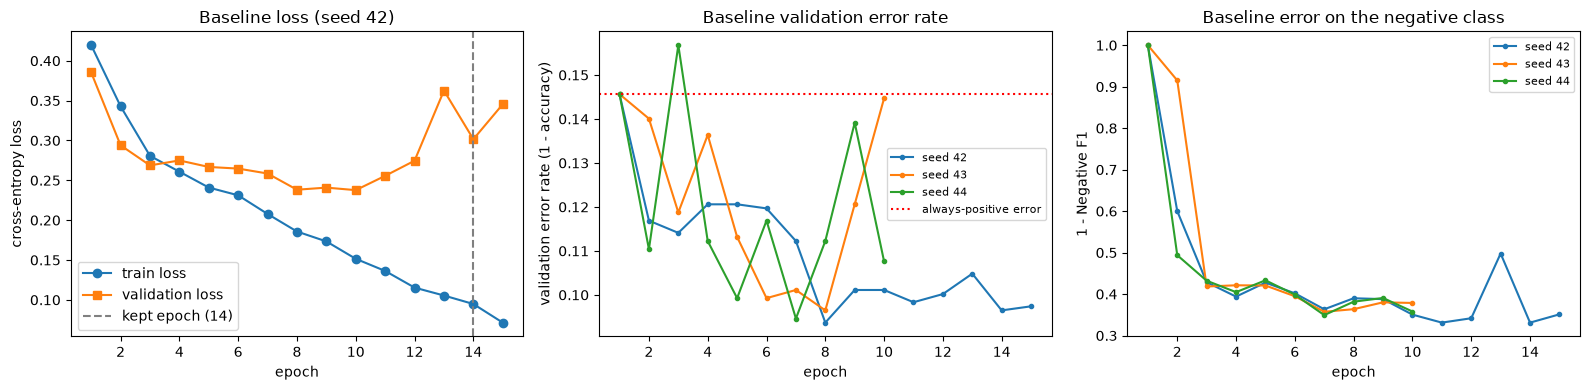

In [6]:
# ==================== BASELINE ERROR CURVES ====================
# The history of each run holds, per epoch: train loss, validation loss, validation accuracy and validation
# Negative F1 (training error rate is not recorded, only training loss).
histories = {int(json.loads(r["config"])["seed"]): pd.DataFrame(
                 json.loads((RESULTS / "histories" / f"{r['key']}.json").read_text()))
             for r in baseline_rows}
kept = {int(json.loads(r["config"])["seed"]): r["best_epoch"] for r in baseline_rows}

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
# (1) Loss for seed 42. Training loss keeps falling; validation loss turning upward means the model starts
#     memorising the training reviews (overfitting). The dashed line is the epoch whose weights were kept.
h = histories[SEED]
ax[0].plot(h["epoch"], h["train_loss"], "o-", label="train loss")
ax[0].plot(h["epoch"], h["val_loss"], "s-", label="validation loss")
ax[0].axvline(kept[SEED], color="gray", ls="--", label=f"kept epoch ({kept[SEED]})")
ax[0].set(xlabel="epoch", ylabel="cross-entropy loss", title=f"Baseline loss (seed {SEED})"); ax[0].legend()
# (2) Validation error rate = 1 - accuracy, every seed. The dotted line is the error of a model that always
#     answers "positive" (about 14.6%); a useful model must stay below it.
for s, hh in histories.items():
    ax[1].plot(hh["epoch"], 1 - hh["val_acc"], "o-", ms=3, label=f"seed {s}")
ax[1].axhline(min(np.mean(val_y), 1 - np.mean(val_y)), color="red", ls=":", label="always-positive error")
ax[1].set(xlabel="epoch", ylabel="validation error rate (1 - accuracy)", title="Baseline validation error rate")
ax[1].legend(fontsize=8)
# (3) Error on the negative class = 1 - Negative F1. It starts at 1.0 because early on the model predicts
#     "positive" for everything, then drops once it learns to find negative reviews.
for s, hh in histories.items():
    ax[2].plot(hh["epoch"], 1 - hh["val_neg_f1"], "o-", ms=3, label=f"seed {s}")
ax[2].set(xlabel="epoch", ylabel="1 - Negative F1", title="Baseline error on the negative class")
ax[2].legend(fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS / "baseline_error_curve.png", dpi=150); plt.show()

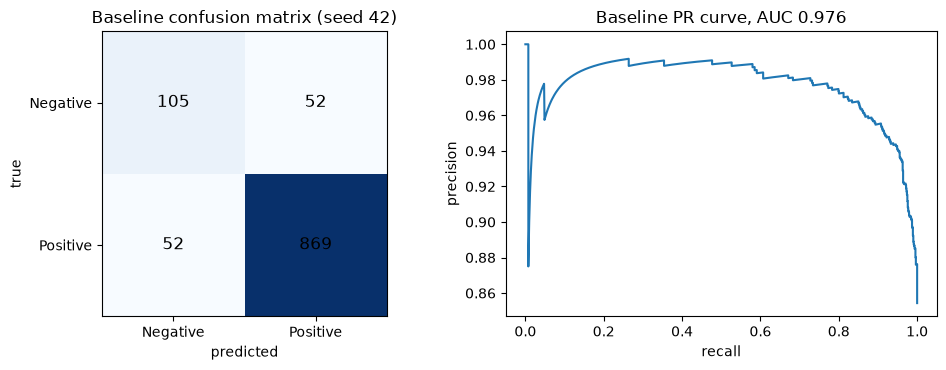

negative reviews found: 105 of 157  |  positive reviews kept: 869 of 921


In [7]:
# ==================== BASELINE CONFUSION MATRIX AND PR CURVE (SEED 42) ====================
from sklearn.metrics import confusion_matrix, precision_recall_curve

run42 = baseline_rows[0]                                            # the seed-42 baseline run
probs = np.load(RESULTS / "probs" / f"{run42['key']}.npy")          # P(positive) for each validation review
pred = (probs >= 0.5).astype(int)   # decision rule: predict positive when P(positive) >= 0.5
y = np.asarray(val_y)               # true labels of the validation reviews

# Confusion matrix: rows = true class, columns = predicted class.
# Example reading: the top-right cell counts negative reviews wrongly called positive (false positives).
cm = confusion_matrix(y, pred, labels=[0, 1])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[0].text(j, i, int(v), ha="center", va="center", fontsize=12)
ax[0].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"],
          xlabel="predicted", ylabel="true", title="Baseline confusion matrix (seed 42)")

# Precision-recall curve for the positive class: sweeps the 0.5 threshold from 0 to 1.
# Area under it (PR-AUC) near 1.0 means positives are ranked well regardless of the exact threshold.
prec, rec, _ = precision_recall_curve(y, probs)
ax[1].plot(rec, prec)
ax[1].set(xlabel="recall", ylabel="precision", title=f"Baseline PR curve, AUC {run42['pr_auc']:.3f}")
fig.tight_layout(); fig.savefig(RESULTS / "baseline_confusion_pr.png", dpi=150); plt.show()
print(f"negative reviews found: {cm[0, 0]} of {cm[0].sum()}  |  positive reviews kept: {cm[1, 1]} of {cm[1].sum()}")

In [8]:
# ==================== BASELINE ERROR ANALYSIS (validation set) ====================
# The test reviews have no labels, so right/wrong analysis uses the validation set. For each error type take the
# 10 mistakes the model was LEAST sure about: the borderline cases are the most useful to discuss. A mistake with
# P(positive)=0.05 on a positive review would be a confident, serious one.
conf = np.abs(probs - 0.5)      # distance from the 0.5 decision boundary: small = unsure
frames = []
for kind, true_label, pred_label in (("false negative (true positive review)", 1, 0),
                                     ("false positive (true negative review)", 0, 1)):
    idx = np.where((y == true_label) & (pred == pred_label))[0]   # validation rows with this error
    idx = idx[np.argsort(conf[idx])][:10]                          # least confident first
    frames.append(pd.DataFrame({
        "error_type": kind, "p_positive": probs[idx].round(3), "true": y[idx],
        "words": [len(val_texts[i].split()) for i in idx], "review": [val_texts[i] for i in idx],
    }))
errors = pd.concat(frames, ignore_index=True)
errors.to_csv(RESULTS / "baseline_errors.csv", index=False)   # full text of the 20 examples, for the report
print(f"{(pred != y).sum()} misclassified of {len(y)}; wrote {len(errors)} examples to baseline_errors.csv")
# Print 3 of each type. Things to look for: negation ("not bad"), sarcasm, mixed sentiment, long reviews.
for _, r in errors.groupby("error_type").head(3).iterrows():
    print(f"\n[{r.error_type}] p(pos)={r.p_positive} words={r.words}\n{r.review[:300]}")

104 misclassified of 1078; wrote 20 examples to baseline_errors.csv

[false negative (true positive review)] p(pos)=0.4860000014305115 words=83
I used to wear these when I was a deep sea diver in the navy back in 77-81. We ran 10k (6.2 mi) everyday. I went through 2 pair back in the day. These shoes feel like a custom leather glove once they're broken in and look very cool w straight leg jeans. They carried me all over the back alleys of Eu

[false negative (true positive review)] p(pos)=0.4779999852180481 words=243
I originally bought the Case Logic Quick-Lock 320 CD case... as soon as I got it home and loaded it up with CD's, I knew it just wasn't going to work, moving pages around was a huge hassle, you had to remove EVERY page first, and putting them back in wasn't easy... So...I went with this case. It's b

[false negative (true positive review)] p(pos)=0.4729999899864197 words=65
I bought another of Clark's sandals a few years ago, which is why I ordered them again. These sandals

In [9]:
# ==================== SANITY CHECKS ====================
# Accuracy of a model that always answers "positive": the bar any real model must clear (about 0.854).
ALWAYS_POSITIVE = max(np.mean(val_y), 1 - np.mean(val_y))
# Every metric must be a valid proportion; a value outside [0, 1] would mean a bug.
assert table[["accuracy", "neg_f1", "pr_auc"]].apply(lambda c: c.between(0, 1)).all().all()
print(f"always-positive baseline accuracy: {ALWAYS_POSITIVE:.4f}")
print(f"baseline model (mean of 3 seeds): accuracy {summary['mean']['accuracy']:.4f}, "
      f"Negative F1 {summary['mean']['neg_f1']:.4f}")
if summary["mean"]["accuracy"] <= ALWAYS_POSITIVE:
    print("NOTE: the baseline does not beat the always-positive baseline on accuracy; "
          "rely on Negative F1 and PR-AUC when interpreting it.")

always-positive baseline accuracy: 0.8544
baseline model (mean of 3 seeds): accuracy 0.9026, Negative F1 0.6540


## How to read these numbers (limitations)

- **The validation scores are optimistic.** The same 1,078 validation reviews (only 157 negative) choose the early-stopping epoch and are used to report the scores. No unbiased estimate is available here because the test set has no labels.
- **Epoch-to-epoch scores are noisy.** Validation accuracy can move by several points between consecutive epochs (see the error-curve plot), so early stopping on a single epoch's Negative F1 can keep a lucky epoch rather than the epoch with the lowest validation loss.
- **Three seeds give a rough noise estimate** (n = 3). The seeds change only the training seed (initialisation of the LSTM and classifier, batch order, dropout); the random vectors used for words missing from GloVe always come from seed 42.
- **Settings fixed for the baseline:** layers, dropout, batch size (all three are searched in the next section), direction, `MAX_LEN` (150), GloVe dimension (100), max 15 epochs with patience 3.

# Random search (hold-out validation)

The baseline used one set of default settings. Here we search for better ones for five hyperparameters: **hidden units, number of LSTM layers, learning rate, dropout and batch size**.

**Why random search:** a grid over five settings multiplies quickly (3 x 2 x 5 x 5 x 3 = 450 runs). Random search samples N configurations from the whole space instead; it tries each setting at many distinct values (a grid repeats the same few), which usually finds comparably good settings in far fewer runs. The learning rate is sampled on a **log scale** because 1e-4 vs 1e-3 matters as much as 1e-3 vs 1e-2.

**How each candidate is judged:** every configuration is trained on the **full training split** and scored on the **validation split**; the best Negative F1 wins. Each run keeps its own best epoch (early stopping, patience 3). The training data is not split any further.

**Making the choice defensible:**
- The baseline is scored in exactly the same way, so the comparison is like for like.
- A candidate only counts as *better* if it beats the baseline by more than the seed noise (the spread of the baseline's Negative F1 over 3 seeds); otherwise the search found no proven improvement.
- The winner is retrained with 3 seeds and reported as mean ± std. The seed-42 run is the one that was selected (so it is the most flattering); seeds 43 and 44 are the fairer check.

| Fixed (as in the baseline) | Searched |
|---|---|
| frozen GloVe 100d, attention pooling, bidirectional, unweighted loss, AdamW, clip 1.0, up to 15 epochs with early stopping (patience 3) | hidden units, layers, learning rate, dropout, batch size |

Every run is cached by its exact settings, so interrupting and re-running the notebook never repeats work.

In [10]:
# ==================== RANDOM SEARCH SETUP ====================
from src.glove_bilstm import sample_configs

N_ITER = 10       # random configurations to try (the baseline is scored too, for comparison)
SEARCH_SEED = 42  # fixes which configurations are sampled

# The search space. Lists = pick one value. ("uniform", a, b) = number between a and b.
# ("loguniform", a, b) = number between a and b, uniform on a log scale.
SPACE = {
    "hidden": [64, 128, 256],               # LSTM state size per direction
    "layers": [1, 2],                       # stacked LSTM layers (3 rarely helps and is slow)
    "lr": ("loguniform", 3e-4, 1e-2),       # learning rate. 1e-4 is left out: with early stopping (patience 3)
                                            # that rate never starts predicting negatives (Negative F1 stays 0)
    "dropout": ("uniform", 0.2, 0.6),       # dropout on the review vector (and between layers when layers=2)
    "batch_size": [32, 64, 128],            # reviews per update step
}
SEARCH_KEYS = list(SPACE)

# Candidates: the baseline's own values first, then N_ITER random draws.
# Example candidate: {"hidden": 256, "layers": 1, "lr": 0.00245, "dropout": 0.41, "batch_size": 64}
candidates = [("baseline", {k: BASELINE[k] for k in SEARCH_KEYS})]
candidates += [(f"cand {i + 1:02d}", c) for i, c in enumerate(sample_configs(SPACE, N_ITER, seed=SEARCH_SEED))]

# NOISE (defined in the baseline section) is how big a gain must be to count: the baseline's Negative F1 spread over 3 seeds.
print(f"{len(candidates)} candidates; seed-noise band = {NOISE:.4f} Negative F1")
for name, cfg in candidates:
    print(f"  {name}: " + " ".join(f"{k}={cfg[k]}" for k in SEARCH_KEYS))

11 candidates; seed-noise band = 0.0134 Negative F1
  baseline: hidden=128 layers=1 lr=0.001 dropout=0.4 batch_size=64
  cand 01: hidden=256 layers=1 lr=0.000327 dropout=0.31 batch_size=32
  cand 02: hidden=64 layers=1 lr=0.00322 dropout=0.56 batch_size=32
  cand 03: hidden=256 layers=2 lr=0.000335 dropout=0.24 batch_size=32
  cand 04: hidden=256 layers=1 lr=0.00215 dropout=0.49 batch_size=128
  cand 05: hidden=256 layers=2 lr=0.00065 dropout=0.44 batch_size=32
  cand 06: hidden=64 layers=2 lr=0.000989 dropout=0.26 batch_size=64
  cand 07: hidden=64 layers=1 lr=0.00114 dropout=0.34 batch_size=64
  cand 08: hidden=256 layers=2 lr=0.00508 dropout=0.49 batch_size=128
  cand 09: hidden=64 layers=2 lr=0.000395 dropout=0.32 batch_size=128
  cand 10: hidden=256 layers=2 lr=0.00227 dropout=0.48 batch_size=32


In [11]:
# ==================== RUN THE SEARCH (cached, resumable) ====================
# get_run (from the baseline section) trains one configuration on the full training split, early-stops on the
# validation split, saves the result and the per-epoch history, and reuses a saved run with identical settings.
# The baseline candidate therefore costs nothing: its seed-42 run already exists.
t_search = time.time()
search_rows = []
for name, cfg in candidates:
    row = get_run({**BASELINE, **cfg, "seed": SEED}, name)
    search_rows.append({"name": name, **cfg, "neg_f1": row["neg_f1"], "accuracy": row["accuracy"],
                        "pr_auc": row["pr_auc"], "best_epoch": row["best_epoch"],
                        "train_seconds": row["train_seconds"], "key": row["key"]})
    # Example line: cand 03  negF1 0.7012  acc 0.9201  best epoch 6  hidden=128 layers=1 lr=0.00245 ...
    print(f"{name}  negF1 {row['neg_f1']:.4f}  acc {row['accuracy']:.4f}  best epoch {row['best_epoch']}  "
          + " ".join(f"{k}={cfg[k]}" for k in SEARCH_KEYS) + f"   [{(time.time() - t_search) / 60:.1f} min elapsed]")

baseline  negF1 0.6688  acc 0.9035  best epoch 14  hidden=128 layers=1 lr=0.001 dropout=0.4 batch_size=64   [0.0 min elapsed]
cand 01  negF1 0.5594  acc 0.8933  best epoch 3  hidden=256 layers=1 lr=0.000327 dropout=0.31 batch_size=32   [0.0 min elapsed]
cand 02  negF1 0.6767  acc 0.9007  best epoch 6  hidden=64 layers=1 lr=0.00322 dropout=0.56 batch_size=32   [0.0 min elapsed]
cand 03  negF1 0.6205  acc 0.8831  best epoch 5  hidden=256 layers=2 lr=0.000335 dropout=0.24 batch_size=32   [0.0 min elapsed]
cand 04  negF1 0.6435  acc 0.8952  best epoch 7  hidden=256 layers=1 lr=0.00215 dropout=0.49 batch_size=128   [0.0 min elapsed]
cand 05  negF1 0.7010  acc 0.9193  best epoch 10  hidden=256 layers=2 lr=0.00065 dropout=0.44 batch_size=32   [0.0 min elapsed]
cand 06  negF1 0.6324  acc 0.9072  best epoch 5  hidden=64 layers=2 lr=0.000989 dropout=0.26 batch_size=64   [0.0 min elapsed]
cand 07  negF1 0.6306  acc 0.8924  best epoch 5  hidden=64 layers=1 lr=0.00114 dropout=0.34 batch_size=64   [

,name,hidden,layers,lr,dropout,batch_size,neg_f1,accuracy,pr_auc,best_epoch,train_seconds
0,cand 08,256,2,0.0051,0.49,128,0.7147,0.9156,0.9826,11,989.9
1,cand 05,256,2,0.0006,0.44,32,0.7010,0.9193,0.9826,10,1276.8
2,cand 10,256,2,0.0023,0.48,32,0.6978,0.9100,0.9861,7,1099.4
3,cand 02,64,1,0.0032,0.56,32,0.6767,0.9007,0.9788,6,112.8
4,baseline,128,1,0.0010,0.40,64,0.6688,0.9035,0.9763,14,245.7
5,cand 04,256,1,0.0022,0.49,128,0.6435,0.8952,0.9775,7,359.9
6,cand 09,64,2,0.0004,0.32,128,0.6329,0.8924,0.9760,12,313.5
7,cand 06,64,2,0.0010,0.26,64,0.6324,0.9072,0.9781,5,276.3
8,cand 07,64,1,0.0011,0.34,64,0.6306,0.8924,0.9780,5,144.8
9,cand 03,256,2,0.0003,0.24,32,0.6205,0.8831,0.9789,5,836.1


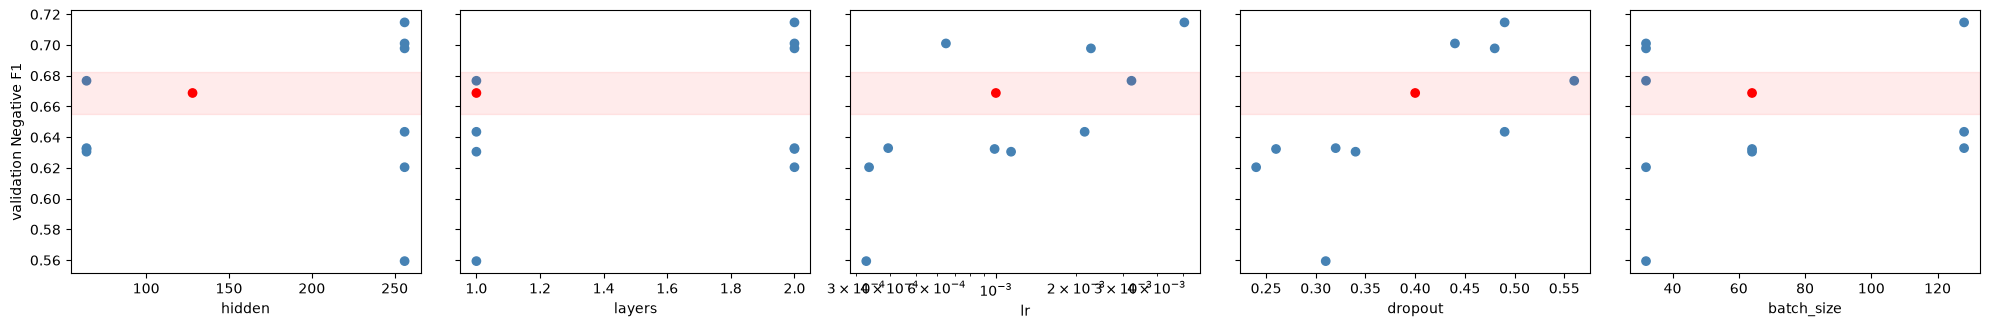

In [12]:
# ==================== SEARCH RESULTS ====================
# All candidates ranked by validation Negative F1.
search = pd.DataFrame(search_rows).sort_values("neg_f1", ascending=False).reset_index(drop=True)
search.drop(columns="key").to_csv(RESULTS / "random_search_summary.csv", index=False)
display(search.drop(columns="key").round(4))

# Which settings matter? One panel per searched setting: each dot is one candidate (the baseline is red).
# A setting that matters shows a clear trend; a flat cloud means the score barely depends on it.
fig, axes = plt.subplots(1, len(SEARCH_KEYS), figsize=(4 * len(SEARCH_KEYS), 3.4), sharey=True)
for ax, key in zip(axes, SEARCH_KEYS):
    ax.scatter(search[key], search["neg_f1"], c=["red" if n == "baseline" else "steelblue" for n in search["name"]])
    ax.axhspan(search[search["name"] == "baseline"]["neg_f1"].iloc[0] - NOISE,
               search[search["name"] == "baseline"]["neg_f1"].iloc[0] + NOISE, color="red", alpha=0.08)
    if key == "lr":
        ax.set_xscale("log")
    ax.set_xlabel(key)
axes[0].set_ylabel("validation Negative F1")
fig.tight_layout(); fig.savefig(RESULTS / "random_search.png", dpi=150); plt.show()   # red band = baseline +- noise

In [13]:
# ==================== BEST CONFIGURATION: 3 SEEDS vs BASELINE ====================
# Selection rule: highest validation Negative F1. It only counts as an improvement if it beats the baseline by
# more than NOISE (the baseline's own seed-to-seed spread); otherwise the search found nothing proven.
best_row = search.iloc[0]
baseline_row = search[search["name"] == "baseline"].iloc[0]
best_cfg = {k: (int(best_row[k]) if k in ("hidden", "layers", "batch_size") else float(best_row[k])) for k in SEARCH_KEYS}
gain = best_row["neg_f1"] - baseline_row["neg_f1"]
print(f"Best candidate: {best_row['name']}  Negative F1 {best_row['neg_f1']:.4f}  (baseline {baseline_row['neg_f1']:.4f}, "
      f"gain {gain:+.4f}, noise band {NOISE:.4f})")
print("Best settings:", best_cfg)
print("-> clear improvement over the baseline" if gain > NOISE else
      "-> NOTE: the gain is within seed noise; treat the improvement as unproven")

# Retrain the best settings with seeds 42, 43, 44. The seed-42 run is the one that was SELECTED (cached, free), so
# it is the most flattering; seeds 43 and 44 are fresh draws and a fairer check of the true quality.
tuned_rows = [get_run({**BASELINE, **best_cfg, "seed": s}, f"tuned seed {s}") for s in (42, 43, 44)]

metrics = ["accuracy", "neg_f1", "pr_auc", "f1"]
compare = pd.DataFrame({
    "baseline mean": {k: np.mean([r[k] for r in baseline_rows]) for k in metrics},
    "baseline std": {k: np.std([r[k] for r in baseline_rows], ddof=1) for k in metrics},
    "tuned mean (3 seeds)": {k: np.mean([r[k] for r in tuned_rows]) for k in metrics},
    "tuned std": {k: np.std([r[k] for r in tuned_rows], ddof=1) for k in metrics},
    "tuned mean (seeds 43, 44 only)": {k: np.mean([r[k] for r in tuned_rows[1:]]) for k in metrics},
})
display(compare.round(4))
(RESULTS / "tuned_summary.json").write_text(json.dumps({"config": best_cfg, "gain_over_baseline": gain, "noise": NOISE,
                                                         "compare": compare.to_dict()}, indent=2, default=float))

Best candidate: cand 08  Negative F1 0.7147  (baseline 0.6688, gain +0.0459, noise band 0.0134)
Best settings: {'hidden': 256, 'layers': 2, 'lr': 0.00508, 'dropout': 0.49, 'batch_size': 128}
-> clear improvement over the baseline


,baseline mean,baseline std,tuned mean (3 seeds),tuned std,"tuned mean (seeds 43, 44 only)"
accuracy,0.9026,0.0033,0.9159,0.0051,0.9160
neg_f1,0.6540,0.0134,0.7089,0.0093,0.7060
pr_auc,0.9793,0.0026,0.9839,0.0012,0.9846
f1,0.9433,0.0021,0.9508,0.0033,0.9510


1112

## How to read the search results (limitations)

- **Optimistic scores.** The validation split picks each run's stopping epoch, picks the winning configuration, and reports its score, and there is no other labeled data to check it (the test set has no labels). The tuned scores are therefore biased upward; the seed-42 row most of all, because it is the run that was selected. Compare seeds 43 and 44 for a fairer view.
- **Selection by luck.** With only 157 negative validation reviews, Negative F1 moves by about 0.013 between seeds, and the best of 10 candidates is partly the luckiest. A gain smaller than the noise band is not evidence of a better configuration.
- **Small budget.** 10 random candidates is a light search of a 5-dimensional space. Read the plot for trends rather than treating the top row as the optimum.
- **One seed per candidate** during the search (seed 42); only the winner and the baseline get 3 seeds.
- **Not searched:** embeddings (kept frozen), pooling, direction, class weighting, optimizer, weight decay, `MAX_LEN`. Whether fine-tuning the GloVe vectors helps is a separate experiment and is not part of this search.

## Error analysis of the best tuned model (validation set, seed 42)

In [14]:
# ==================== ERROR ANALYSIS OF THE BEST TUNED MODEL (validation set, seed 42) ====================
# Same method as the baseline error analysis: the 10 least-confident mistakes of each type. P(positive) comes
# from the saved seed-42 run of the tuned settings.
from sklearn.metrics import confusion_matrix

ty = np.asarray(val_y)
tp = np.load(RESULTS / "probs" / f"{tuned_rows[0]['key']}.npy")
tpred = (tp >= 0.5).astype(int)
base_probs = np.load(RESULTS / "probs" / f"{baseline_rows[0]['key']}.npy")
base_wrong = int(((base_probs >= 0.5).astype(int) != ty).sum())
print("confusion matrix [[TN FP],[FN TP]]:\n", confusion_matrix(ty, tpred, labels=[0, 1]))
print(f"{(tpred != ty).sum()} misclassified of {len(ty)}; the seed-42 baseline had {base_wrong}")
tconf = np.abs(tp - 0.5)      # distance from the 0.5 decision boundary: small = unsure
frames = []
for kind, tl, pl in (("false negative (true positive review)", 1, 0), ("false positive (true negative review)", 0, 1)):
    idx = np.where((ty == tl) & (tpred == pl))[0]
    idx = idx[np.argsort(tconf[idx])][:10]
    frames.append(pd.DataFrame({"error_type": kind, "p_positive": tp[idx].round(3), "words": [len(val_texts[i].split()) for i in idx],
                                "review": [val_texts[i] for i in idx]}))
tuned_errors = pd.concat(frames, ignore_index=True)
tuned_errors.to_csv(RESULTS / "tuned_errors.csv", index=False)
for _, r in tuned_errors.groupby("error_type").head(4).iterrows():
    print(f"\n[{r.error_type}] p(pos)={r.p_positive} words={r.words}\n{r.review[:300]}")

confusion matrix [[TN FP],[FN TP]]:
 [[114  43]
 [ 48 873]]
91 misclassified of 1078; the seed-42 baseline had 104

[false negative (true positive review)] p(pos)=0.47099998593330383 words=12
Bealls got this product here and on time. Nothing else to say

[false negative (true positive review)] p(pos)=0.4659999907016754 words=13
These are simply the best sport sandals ever created. I wear none other

[false negative (true positive review)] p(pos)=0.44600000977516174 words=55
If there is a power shortage, or any other type of emergency, this is better than a flashlight, because it can be lifted off of it's base and carried to any location you want to light. I have put one in every closet, and they have been very helpful in locating clothes in dark places

[false negative (true positive review)] p(pos)=0.4350000023841858 words=150
I have been looking for a pair of Docs for a while. I know they are a new globalized company, and I am not necessarily against that. I am disappointed that you 

**Findings.** 91 errors (48 missed positives, 43 false alarms); negatives found 114/157 (recall 0.73), positives kept 873/921. Mistakes are mostly borderline (p between 0.43 and 0.65), not confident. Error rate does not grow with length (7–10% in every length bucket). Patterns: (1) mixed or weak-sentiment reviews ("I love the look... a little smaller than marked") flagged negative; (2) complaints without strong negative words, or about shipping/seller/price rather than the product, flagged positive; (3) neutral/question-style reviews and polite or sarcastic phrasing ("thanks 4 nothing") that needs context; (4) short vague positives ("Nothing else to say").

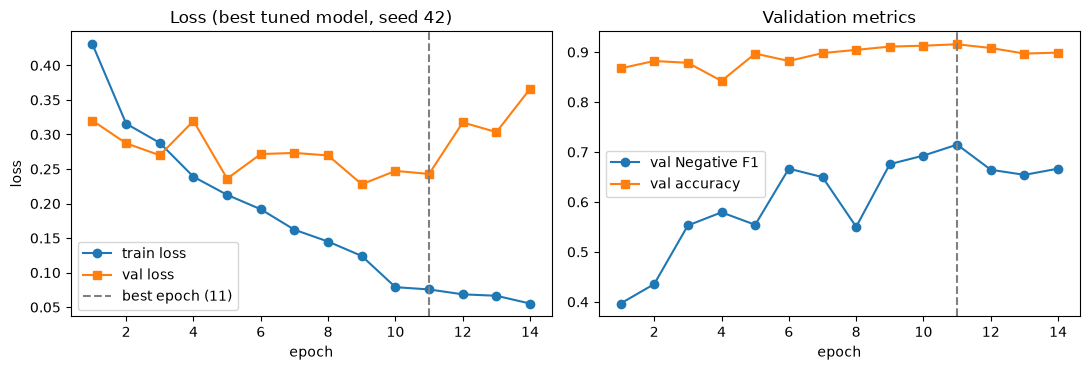

In [15]:
# ==================== TRAIN VS VALIDATION LOSS (best tuned model, seed 42) ====================
th = pd.DataFrame(json.loads((RESULTS / "histories" / f"{tuned_rows[0]['key']}.json").read_text()))
best_ep = int(th.loc[th["val_neg_f1"].idxmax(), "epoch"])   # epoch whose weights were restored

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(th["epoch"], th["train_loss"], "o-", label="train loss")
ax[0].plot(th["epoch"], th["val_loss"], "s-", label="val loss")
ax[0].axvline(best_ep, color="gray", ls="--", label=f"best epoch ({best_ep})")
ax[0].set(xlabel="epoch", ylabel="loss", title="Loss (best tuned model, seed 42)"); ax[0].legend()
ax[1].plot(th["epoch"], th["val_neg_f1"], "o-", label="val Negative F1")
ax[1].plot(th["epoch"], th["val_acc"], "s-", label="val accuracy")
ax[1].axvline(best_ep, color="gray", ls="--")
ax[1].set(xlabel="epoch", title="Validation metrics"); ax[1].legend()
fig.tight_layout(); fig.savefig(RESULTS / "tuned_loss_curve.png", dpi=150); plt.show()

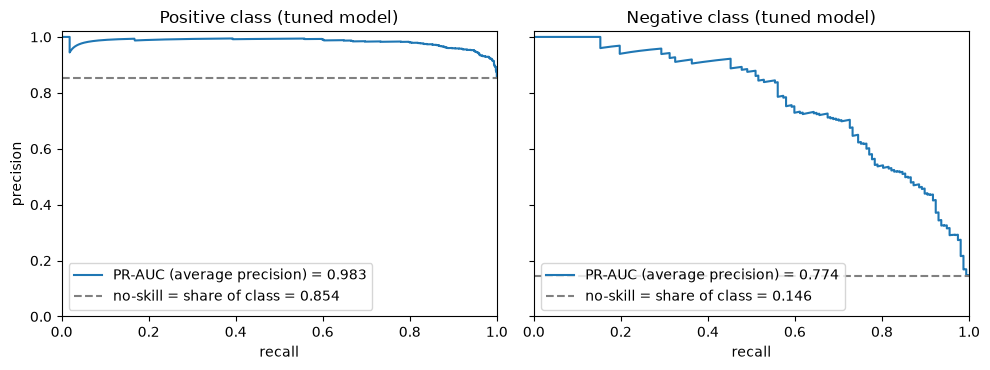

In [16]:
# ==================== PR CURVES: POSITIVE CLASS AND NEGATIVE CLASS (best tuned model, seed 42) ====================
from sklearn.metrics import average_precision_score, precision_recall_curve
pr_probs = np.load(RESULTS / "probs" / f"{tuned_rows[0]['key']}.npy")   # P(positive) for each validation review
pr_y = np.asarray(val_y)

# Positive class: score = P(positive), "positive" label = 1.  Negative class: score = P(negative) = 1 - P(positive), label = 0.
curves = {"Positive class": (pr_y == 1, pr_probs), "Negative class": (pr_y == 0, 1 - pr_probs)}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for a, (name, (truth, score)) in zip(ax, curves.items()):
    prec, rec, _ = precision_recall_curve(truth, score)
    ap = average_precision_score(truth, score)
    a.plot(rec, prec, label=f"PR-AUC (average precision) = {ap:.3f}")
    a.axhline(truth.mean(), color="gray", ls="--", label=f"no-skill = share of class = {truth.mean():.3f}")
    a.set(xlabel="recall", title=f"{name} (tuned model)", xlim=(0, 1), ylim=(0, 1.02)); a.legend(loc="lower left")
ax[0].set_ylabel("precision")
fig.tight_layout(); fig.savefig(RESULTS / "tuned_pr_curves.png", dpi=150); plt.show()

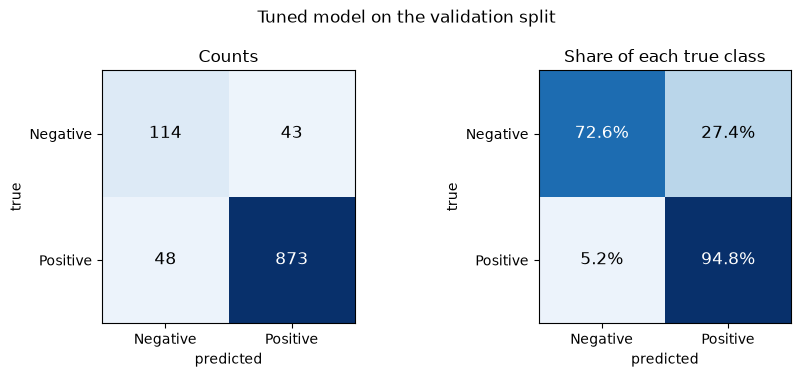

In [17]:
# ==================== CONFUSION MATRIX (best tuned model, seed 42, threshold 0.5) ====================
from sklearn.metrics import confusion_matrix
cm_y = np.asarray(val_y)
cm_pred = (np.load(RESULTS / "probs" / f"{tuned_rows[0]['key']}.npy") >= 0.5).astype(int)
cm_counts = confusion_matrix(cm_y, cm_pred, labels=[0, 1])               # [[TN, FP], [FN, TP]]
cm_rates = cm_counts / cm_counts.sum(axis=1, keepdims=True)              # each row sums to 1 = share of that true class

fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a, mat, title, fmt in ((ax[0], cm_counts, "Counts", "{:d}"), (ax[1], cm_rates, "Share of each true class", "{:.1%}")):
    a.imshow(mat, cmap="Blues", vmin=0, vmax=mat.max())
    for (i, j), v in np.ndenumerate(mat):
        a.text(j, i, fmt.format(v), ha="center", va="center", color="white" if v > mat.max() / 2 else "black", fontsize=12)
    a.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"],
          xlabel="predicted", ylabel="true", title=title)
fig.suptitle("Tuned model on the validation split")
fig.tight_layout(); fig.savefig(RESULTS / "tuned_confusion.png", dpi=150); plt.show()